# Sequential monitors that keep their size when read every day

**Question:** A validation desk reads its back-tests every day and its calibration every year. Read that way, how often does a
fixed-window test reject a correct model, can a monitor read at every step keep a 5 % size, and what does that size cost in delay
and in power, on known truths and on the real windows of cases C11 and C03?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01 to 03 of this topic (size, power and Monte Carlo error) and notebook 03 of topic 07 (the
  back-tests)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- say why a test valid when read once loses its size when it is read every day, and measure by how much;
- build the e-process of a VaR hit rate by hand as an average of bets, and read Ville's inequality off it;
- compare, on the case's generators, the size and the detection delay of the e-process with Kupiec's test, the Basel traffic light
  and the independence test read the way a desk reads them;
- test the case's claim against the rules written before the run, and read the monitor on the real hits of C11 and the vintages
  of C03.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you.
A notebook never installs anything by itself. The next cell imports what the notebook uses, puts the case pipeline on the path and
prints the versions.

In [1]:
# Import the tools, put the case pipeline on the path and print the versions they run with
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.hits import VarHits
from riskvalidation.validation import market as vm
from riskvalidation.validation.sequential import pd_grades, var_hits

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c22_sequential as seq
from pipeline.cases.c03 import sequential as c03_seq

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed documents feed the notebook. Case C22 measures the tests themselves on generators of known truth; its document of
other families carries the sequential study: 2,000 series of VaR hits per scenario over 1,000 days from the engine's `VarHits`
generator, and 2,000 books of defaults by grade over ten years. Case C11 back-tests 18 VaR models on real windows; the notebook reads
the hit days at 1 % of every model in equity 2007 to 2009 (504 days) and in the euro against the dollar in 2008 (251 days). Case C03
follows SBA 7(a) loan vintages; each cohort document carries, by vintage, the predicted and the observed cumulative default curves
at 12 to 60 months.

In [2]:
# Read the committed documents: the study of case C22, two windows of C11 with every model's hits, C03's cohorts
DERIVED = ROOT / "data" / "derived"
block = json.loads((DERIVED / "C22" / "other-families.json").read_text(encoding="utf-8"))["outputs"]["sequential"]
hits_study, pd_study = block["hits"], block["pd_grades"]
c11 = {}
for w in ("equity-2007-09", "fx-2008"):
    c11[w] = json.loads((DERIVED / "C11" / f"{w}.json").read_text(encoding="utf-8"))["outputs"]
c03 = {}
for c in ("fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"):
    c03[c] = json.loads((DERIVED / "C03" / f"{c}.json").read_text(encoding="utf-8"))["outputs"]
print(f"C22: {hits_study['reps']} series x {len(hits_study['scenarios'])} scenarios, "
      f"{hits_study['horizon']} days, seed {block['seed']}")
for w, o in c11.items():
    print(f"C11 {w}: {len(o['grid']['dates'])} days, {len(o['models'])} models")
for c, o in c03.items():
    print(f"C03 {c}: {len(o['vintage_curves'])} vintages, ages (months) {o['sequential']['months']}")


C22: 2000 series x 7 scenarios, 1000 days, seed 42
C11 equity-2007-09: 504 days, 18 models
C11 fx-2008: 251 days, 18 models
C03 fy2006-07: 2 vintages, ages (months) [12, 24, 36, 48, 60]
C03 fy2008-10: 3 vintages, ages (months) [12, 24, 36, 48, 60]
C03 fy2011-14: 4 vintages, ages (months) [12, 24, 36, 48, 60]
C03 fy2015-17: 3 vintages, ages (months) [12, 24, 36, 48, 60]
C03 fy2018-20: 3 vintages, ages (months) [12, 24, 36, 48, 60]


## Method

A test such as Kupiec's is valid when it is read once, on a window fixed in advance: the chance that it rejects a correct model is
then its level, 5 %. A desk does not read it once. It reads the trailing 250 days, or all the days so far, every morning, and acts
on the first red. Each reading is another chance of a false alarm, and over 1,000 mornings the chances add up. The next cell takes
one correct VaR at 1 %, whose hits are independent with probability exactly 1 %, and reads it three ways: Kupiec's test on all the
days so far, the Basel traffic light on the trailing 250 days, and the engine's e-process.

In [3]:
# One correct VaR at 1 %: 1,000 days of hits at the right rate, read every day by three rules
h = VarHits(t=1000, alpha=0.01, with_var=False).draw(np.random.default_rng(8))["hits"]
e = var_hits.var_hit_eprocess(h, 0.01)
days = np.arange(1, 1001)
kupiec_daily = np.array([vm.kupiec_pof(h[:t], 0.01).p_value for t in days])
below = kupiec_daily[49:] < 0.05
first_kupiec = int(np.argmax(below)) + 50 if below.any() else None
light_day, k_min = seq.basel_first_non_green(h[None, :].astype(bool))
print(f"hits: {int(h.sum())} | expected: 10")
print(f"e-process: max log E {e.log_e.max():.2f} | threshold log 20 {np.log(20):.2f} | rejected {e.rejected}")
print(f"Kupiec read every day: first day below 0.05 {first_kupiec} | days below 0.05 {int(below.sum())}")
print(f"traffic light ({k_min} exceptions in 250 days): leaves green on day {light_day[0]:.0f}")


hits: 8 | expected: 10
e-process: max log E 2.07 | threshold log 20 3.00 | rejected False
Kupiec read every day: first day below 0.05 192 | days below 0.05 422
traffic light (5 exceptions in 250 days): leaves green on day 817


The series has 8 hits in 1,000 days, 10 expected: nothing is wrong with the model. Kupiec's test on all the days so far falls
below 0.05 for the first time on day 192 and stays below it on 422 of the 951 days it is read, and the traffic light, which turns
amber at 5 exceptions in 250 days, leaves the green zone on day 817. A desk acting on the first red of either rule would have rejected
this model. The e-process peaks at a log E of 2.07, below the threshold log 20 = 3.00, and never rejects.

An e-process is a bet against the null. Each day the monitor stakes on an alternative hit rate $m\alpha$; the likelihood
ratio of that alternative against $\alpha$,

$$E_t(m) = \prod_{s \le t} \Big(m^{h_s} \Big(\frac{1 - m\alpha}{1 - \alpha}\Big)^{1 - h_s}\Big),$$

has mean 1 under the null at every day, and so does any fixed average of such bets. Ville's inequality bounds the chance that such
a process ever reaches $1/a$: $P(\sup_t E_t \ge 1/a) \le a$. Rejecting the first time $E_t \ge 20$ therefore has a size of at most
5 % however often it is read and whenever the desk stops. The engine averages eight bets, $m$ from 0.25 to 10; the next cell builds
that average by hand.

In [4]:
# The bet by hand: each alternative rate m alpha is a likelihood ratio against alpha; the e-process is their average
grid = np.array([0.25, 0.5, 1.5, 2, 3, 4, 6, 10])
step = np.where(h[:, None] == 1, np.log(grid), np.log((1 - grid * 0.01) / (1 - 0.01)))
log_lr = np.cumsum(step, axis=0)
log_e = np.log(np.exp(log_lr).mean(axis=1))
print(f"the average of the bets is the engine's e-process: {np.allclose(log_e, e.log_e)}")
for m, final in zip(grid, log_lr[-1]):
    print(f"m {m:5.2f} | log LR {final:7.2f}")
single = var_hits.var_hit_eprocess(h, 0.01, multipliers=[3.0])
print(f"one bet, m = 3: log E {single.log_e[-1]:.2f} | the eight bets: log E {e.log_e[-1]:.2f}")
print(f"anytime-valid p-value: {e.anytime_p_value:.3f}")


the average of the bets is the engine's e-process: True
m  0.25 | log LR   -3.60
m  0.50 | log LR   -0.55
m  1.50 | log LR   -1.78
m  2.00 | log LR   -4.53
m  3.00 | log LR  -11.46
m  4.00 | log LR  -19.44
m  6.00 | log LR  -37.08
m 10.00 | log LR  -76.13
one bet, m = 3: log E -11.46 | the eight bets: log E -2.32
anytime-valid p-value: 0.127


The average of the eight bets is the engine's e-process to rounding. Each bet's final log likelihood ratio shows where the
series sits: every bet ended below where it started, the bet closest to the truth (0.5) lost least, -0.55, and the bet on ten times
the rate lost most, -76.13. The engine's single bet at $m = 3$ gives the -11.46 of that row, and the average of the eight ends at a
log E of -2.32, a wealth of about 0.1. The anytime-valid p-value, $\min(1, 1/\sup_t E_t)$, is 0.127: valid at whatever day it is read. The
figure sets this series beside one whose hit rate is three times too high.

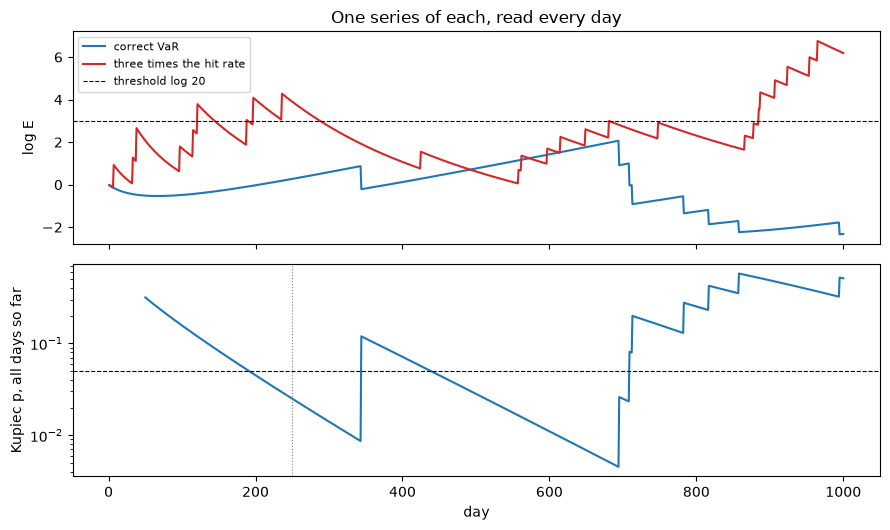

three times the hit rate: hits 25 | e-process day 121 | traffic light day 250


In [5]:
# Draw log E of the correct series and of a series with three times the hit rate, and the daily Kupiec p-value
h3 = VarHits(t=1000, alpha=0.01, with_var=False, rate_factor=3.0).draw(np.random.default_rng(7))["hits"]
e3 = var_hits.var_hit_eprocess(h3, 0.01)
light3, _ = seq.basel_first_non_green(h3[None, :].astype(bool))
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True)
top.plot(days, e.log_e, color="tab:blue", label="correct VaR")
top.plot(days, e3.log_e, color="tab:red", label="three times the hit rate")
top.axhline(np.log(20), color="black", linestyle="--", linewidth=0.8, label="threshold log 20")
top.set_ylabel("log E")
top.set_title("One series of each, read every day")
top.legend(fontsize=8)
bottom.plot(days[49:], kupiec_daily[49:], color="tab:blue")
bottom.axhline(0.05, color="black", linestyle="--", linewidth=0.8)
bottom.axvline(250, color="grey", linestyle=":", linewidth=0.8)
bottom.set_yscale("log")
bottom.set_xlabel("day")
bottom.set_ylabel("Kupiec p, all days so far")
fig.tight_layout()
plt.show()
print(f"three times the hit rate: hits {int(h3.sum())} | e-process day {e3.rejection_time} | "
      f"traffic light day {light3[0]:.0f}")


The top panel is log E. The correct series (blue) climbs slowly while hits are scarce, to 2.07 near day 690, and falls with
each hit after that, never reaching the dashed threshold; the series with three times the hit rate (red) crosses it on day 121, about
six months of trading in, where the traffic light, which cannot speak
before it has 250 days, flags it on day 250. The bottom panel is Kupiec's p-value on all the days so far, for the correct series,
on a log scale: it sits under the dashed 0.05 line in two long stretches, from day 192 to about day 345 and from about day 440 to
about day 710, with too few hits for the days so far. That is the false alarm the e-process is built to avoid.

## Comparison

The methods compared are the published tests read as a desk reads them: Kupiec's test on the trailing 250 days and on all the days
so far, both read every day; the Basel traffic light, the first day the trailing 250-day count of exceptions leaves the green zone;
Christoffersen's independence test on the trailing 250 days, read every day; and, as the reference for power, Kupiec's test read
once on the first 250 days. Against them stand the e-process of the hit rate, the e-process of clustering (a hit after a hit) and
their average, the battery. The case's study runs them on the engine's `VarHits` generator: a correct VaR, a hit rate 2, 3 and 4
times too high, and hits at the right rate that cluster. The next cell reruns it with 200 series per scenario; the committed figure
in brackets has 2,000.

In [6]:
# Rerun the case's study at a tenth of its size, 200 series per scenario, next to the committed 2,000
RULES = ("e_rate", "e_battery", "kupiec_trailing", "kupiec_cumulative", "traffic_light", "independence_trailing")
small = seq.run_hits(20261030, reps=200)
print(f"{'':12s} " + " ".join(f"{r[:16]:>17s}" for r in RULES))
for s in small["scenarios"]:
    committed = next(c for c in hits_study["scenarios"] if c["id"] == s["id"])
    print(f"{s['id']:12s} " + " ".join(f"{s[r]['ever']:7.3f} ({committed[r]['ever']:.3f})" for r in RULES))


                        e_rate         e_battery   kupiec_trailing  kupiec_cumulativ     traffic_light  independence_tra
null           0.025 (0.018)   0.000 (0.013)   0.620 (0.665)   0.330 (0.338)   0.570 (0.587)   0.050 (0.076)
rate-x2        0.550 (0.538)   0.445 (0.456)   0.900 (0.869)   0.890 (0.879)   0.975 (0.992)   0.145 (0.155)
rate-x3        0.965 (0.981)   0.960 (0.974)   1.000 (0.998)   1.000 (0.999)   1.000 (1.000)   0.150 (0.152)
rate-x4        1.000 (1.000)   1.000 (0.999)   1.000 (1.000)   1.000 (1.000)   1.000 (1.000)   0.150 (0.170)
cluster-0.1    0.035 (0.046)   0.245 (0.231)   0.785 (0.755)   0.405 (0.395)   0.555 (0.612)   0.555 (0.571)
cluster-0.2    0.105 (0.071)   0.455 (0.508)   0.845 (0.831)   0.540 (0.495)   0.610 (0.615)   0.740 (0.779)
cluster-0.4    0.145 (0.182)   0.805 (0.795)   0.920 (0.951)   0.680 (0.702)   0.690 (0.668)   0.905 (0.920)


Each entry is the share of series rejected at some day of the 1,000, here over 200 series and in brackets over the committed
2,000; the two agree within the Monte Carlo error of 200 series. On a correct VaR the committed e-process rejects 1.8 % of the series
and the battery 1.3 %. Kupiec's test rejects 66.5 % on the trailing window and 33.8 % on all the days so far, and the traffic light
leaves green in 58.7 %. The figure reads the committed columns.

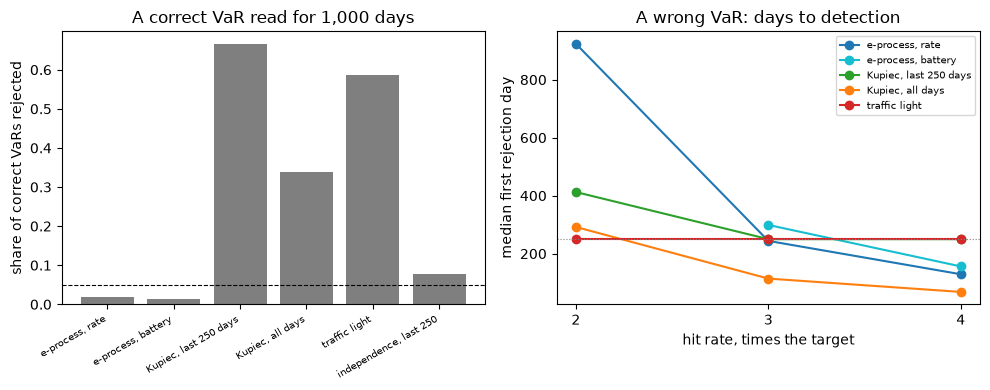

In [7]:
# Draw, from the committed study, how often each rule rejects a correct VaR and how fast each detects a wrong one
null = next(s for s in hits_study["scenarios"] if s["id"] == "null")
wrong = [s for s in hits_study["scenarios"] if s["kind"] == "rate"]
names = ["e-process, rate", "e-process, battery", "Kupiec, last 250 days",
         "Kupiec, all days", "traffic light", "independence, last 250"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.bar(range(len(RULES)), [null[r]["ever"] for r in RULES], color="tab:grey")
left.axhline(0.05, color="black", linestyle="--", linewidth=0.8)
left.set_xticks(range(len(RULES)))
left.set_xticklabels(names, rotation=30, fontsize=7, ha="right")
left.set_ylabel("share of correct VaRs rejected")
left.set_title("A correct VaR read for 1,000 days")
for r, label, color in zip(RULES[:5], names[:5], ("tab:blue", "tab:cyan", "tab:green", "tab:orange", "tab:red")):
    medians = [s[r]["median_day"] or np.nan for s in wrong]
    right.plot([s["factor"] for s in wrong], medians, "o-", color=color, label=label)
right.axhline(250, color="grey", linestyle=":", linewidth=0.8)
right.set_xticks([2, 3, 4])
right.set_xlabel("hit rate, times the target")
right.set_ylabel("median first rejection day")
right.set_title("A wrong VaR: days to detection")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()


The left panel is the size: the dashed line is 5 %, and only the two e-processes and, close to it at 7.6 %, the independence test
sit near it. The right panel is the median first rejection day at a hit rate 2, 3 and 4 times too high. Kupiec's test on all the days
so far is the fastest (114 and 68 days at 3 and 4 times), but that speed is bought with the 33.8 % false alarms of the left panel.
The e-process of the rate needs 244 and 129 days, the traffic light and the trailing Kupiec 250, their first possible day. The
battery, which also bets on clustering, is slower: 299 and 156 days.

The same question holds for a PD. Five grades, with PDs of 0.5 % to 10 % and 2,000 obligors each per year, are followed for ten
years, with every PD multiplied by a factor from 1 (a correct model) to 2. The e-process of defaults by grade combines the grades by
product (independent grades) or by average (any dependence); the comparator is the chi-square test across the grades on the
cumulative counts, read once at year 10 and read every year.

In [8]:
# Defaults against the PD by grade: five grades, ten years, every PD times a factor; 200 books here, 2,000 committed
small_pd = seq.run_pd(20261030, reps=200)
for s, committed in zip(small_pd["scenarios"], pd_study["scenarios"]):
    print(f"x{s['factor']:<5g} | e product {s['e_product']['ever']:.3f} ({committed['e_product']['ever']:.3f}) | "
          f"e average {s['e_average']['ever']:.3f} ({committed['e_average']['ever']:.3f}) | "
          f"chi2 once at year 10 {committed['chi2_one_shot_power']:.3f} | "
          f"chi2 every year {committed['chi2_every_year']['ever']:.3f}")


x1     | e product 0.000 (0.000) | e average 0.000 (0.007) | chi2 once at year 10 0.051 | chi2 every year 0.201
x1.05  | e product 0.000 (0.000) | e average 0.035 (0.044) | chi2 once at year 10 0.679 | chi2 every year 0.790
x1.1   | e product 0.205 (0.247) | e average 0.550 (0.600) | chi2 once at year 10 1.000 | chi2 every year 1.000
x1.25  | e product 1.000 (1.000) | e average 1.000 (1.000) | chi2 once at year 10 1.000 | chi2 every year 1.000
x1.5   | e product 1.000 (1.000) | e average 1.000 (1.000) | chi2 once at year 10 1.000 | chi2 every year 1.000
x2     | e product 1.000 (1.000) | e average 1.000 (1.000) | chi2 once at year 10 1.000 | chi2 every year 1.000


The pattern repeats with a larger price. On a correct PD the e-process rejects 0.0 % (product) and 0.7 % (average) of the
books, where the chi-square read every year rejects 20.1 %. From a factor of 1.25 the e-process detects every book, in two years. A
small error is where the size is paid for: at a factor of 1.1 the single chi-square at year 10 detects every book, the e-process only
24.7 % (product) and 60.0 % (average) within ten years, and at 1.05 the chi-square detects 68 % and the e-process 4.4 % at
best.

## Evidence

The claim, fixed in the SDD before any run, has three parts and a refutation condition. Size: read every day for 1,000 days, the
e-process rejects a correct VaR in at most 5 % plus three standard errors of the series, where the repeated Kupiec test rejects
more. Delay: at a hit rate three and four times too high, its median detection day is below 250 and below the traffic light's.
Power cost: one Kupiec reading at 250 days has less than 10 points more power than the e-process by day 250. It is refuted if the
delay is not lower than the traffic light's on the real windows. The next cell applies the rules of the case to the committed
study.

In [9]:
# The verdict rules written before the run, recomputed from the committed study
v = seq.verdict(hits_study)
h1 = v["H1_size"]
print(f"H1 size: e-process {h1['e_process_size']:.3f} | Kupiec trailing {h1['kupiec_trailing_size']:.3f} | "
      f"Kupiec cumulative {h1['kupiec_cumulative_size']:.3f} | bound {h1['bound']:.4f} | {h1['holds']}")
for sid, d in v["detail"].items():
    print(f"{sid}: median day, e-process / traffic light {d['e_median_day']} / {d['traffic_light_median_day']}")
    print(f"{'':8s}power at 250 days, Kupiec / e-process {d['kupiec_power_250']:.3f} / {d['e_power_by_250']:.3f} | "
          f"cost {d['power_cost']:.3f}")
print(f"H2 {v['H2_delay']['holds']} | H3 {v['H3_power_cost']['holds']} | as a whole {v['holds']}")
print(block["verdict"]["text"]["en"])


H1 size: e-process 0.018 | Kupiec trailing 0.665 | Kupiec cumulative 0.338 | bound 0.0646 | True
rate-x3: median day, e-process / traffic light 244.0 / 250.0
        power at 250 days, Kupiec / e-process 0.622 / 0.503 | cost 0.119
rate-x4: median day, e-process / traffic light 129.0 / 250.0
        power at 250 days, Kupiec / e-process 0.865 / 0.776 | cost 0.089
H2 True | H3 False | as a whole False
The hypothesis does not hold as stated: H3 failed (H1, H2 held). At a hit rate 3 times too high the e-process loses 11.9 points of power at 250 days against one Kupiec reading. Reported as measured; the monitors were not retuned.


The size holds: 1.8 % against a bound of 6.5 %, with Kupiec at 66.5 % and 33.8 %. The delay holds: days 244 and 129 against the
light's 250, which is its first possible day, so the margin at three times the rate is small. The power cost does not hold: one
Kupiec reading at 250 days has 62.2 % power against 50.3 % for the e-process at three times the rate, 11.9 points where the rule
allowed 10; at four times the cost is 8.9 points. So the claim as stated fails, and it is reported that way; the monitors were not
retuned. One qualification belongs beside that number: the single Kupiec reading is not a clean 5 % test here, since the committed
study has it rejecting 10.35 % of correct series at 250 days, so part of its power is size. Next the real windows, with the
refutation condition.

In [10]:
# The real windows of C11: every model's committed hits at 1 %, the e-process against the traffic light
real = {}
for w, o in c11.items():
    n_days = len(o["grid"]["dates"])
    for m in o["models"]:
        lvl = next(b for b in m["by_level"] if b["alpha"] == 0.01)
        flags = np.zeros(n_days, bool)
        flags[lvl["exceedance_days"]] = True
        e_day = var_hits.var_hit_eprocess(flags, 0.01).rejection_time
        light, _ = seq.basel_first_non_green(flags[None, :])
        real[(w, m["model_id"])] = (int(flags.sum()), e_day, light[0])
for w in c11:
    rows = [r for (win, _), r in real.items() if win == w]
    e_days = [d for _, d, _ in rows if d is not None]
    light_days = [d for _, _, d in rows if np.isfinite(d)]
    print(f"{w}: {len(rows)} models | e-process {len(e_days)}, median day {np.median(e_days):.0f} | "
          f"traffic light {len(light_days)}, median day {np.median(light_days):.0f}")
missed = [m for (w, m), (_, d, light) in real.items() if w == "fx-2008" and d is None and np.isfinite(light)]
print(f"fx-2008, flagged by the light, not by the e-process: {missed}")


equity-2007-09: 18 models | e-process 18, median day 24 | traffic light 18, median day 250
fx-2008: 18 models | e-process 9, median day 68 | traffic light 11, median day 250
fx-2008, flagged by the light, not by the e-process: ['caviar-sav', 'caviar-es']


In equity 2007 to 2009 every one of the 18 models is flagged by both rules, the e-process at a median day of 24 and the traffic
light at day 250, the first day it can speak; the refutation condition does not occur. In the euro in 2008 the e-process flags 9
models at a median day of 68, the light 11 at day 250; the two the e-process misses, `caviar-sav` and `caviar-es`, have 5
exceptions in 251 days, exactly the amber threshold, which is not evidence enough for a bet at 20 to 1. The comparison favours the
e-process by construction, since the light reads nothing before day 250; the fair comparison of delay is the generator study above.
The figure shows the 2007 to 2009 window.

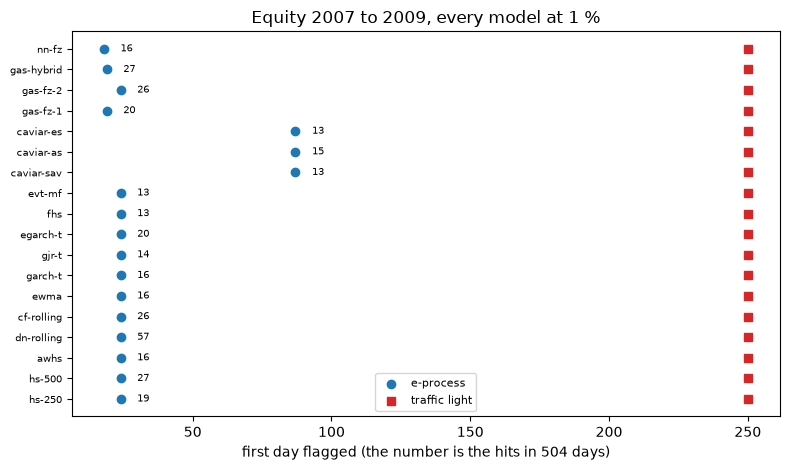

In [11]:
# Draw the first day each model of equity-2007-09 is flagged, by the e-process and by the traffic light
models = [m for (w, m) in real if w == "equity-2007-09"]
y_pos = np.arange(len(models))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter([real[("equity-2007-09", m)][1] for m in models], y_pos, color="tab:blue", label="e-process", zorder=3)
ax.scatter([real[("equity-2007-09", m)][2] for m in models], y_pos, color="tab:red", marker="s", label="traffic light")
for i, m in enumerate(models):
    ax.annotate(str(real[("equity-2007-09", m)][0]), (real[("equity-2007-09", m)][1] + 6, i), fontsize=7, va="center")
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=7)
ax.set_xlabel("first day flagged (the number is the hits in 504 days)")
ax.set_title("Equity 2007 to 2009, every model at 1 %")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


Each row is a model, with its number of hits in 504 days beside the blue point. The red squares stand in one column at day
250, because every model already has more than 4 exceptions when the light first reads. The blue points sit at days 18 to 24 for
most models, the hits of July and August 2007, and at day 87 for the three CAViaR models, whose first hits came later. A desk
reading the e-process would have had its answer in the first month of the crisis instead of after a year.

The last reading is a calibration. In C03 the vintages of a cohort are the grades of the e-process and the ages of 12 to 60
months are its steps; the monitor bets that the observed defaults of each age exceed the predicted ones (the upper direction, the
case a validator is paid to find), and averages the vintages because they share the same economy.

fy2006-07: first age rejected (months) 12 | max log E 11631.0 | 5-year lights ['red', 'red']
fy2008-10: first age rejected (months) 12 | max log E 6362.5 | 5-year lights ['red', 'red', 'green']
fy2011-14: first age rejected (months) None | max log E -2.5 | 5-year lights ['green', 'green', 'green', 'green']
fy2015-17: first age rejected (months) None | max log E -7.3 | 5-year lights ['green', 'green', 'green']
fy2018-20: first age rejected (months) None | max log E 2.4 | 5-year lights ['green', 'green', 'green']


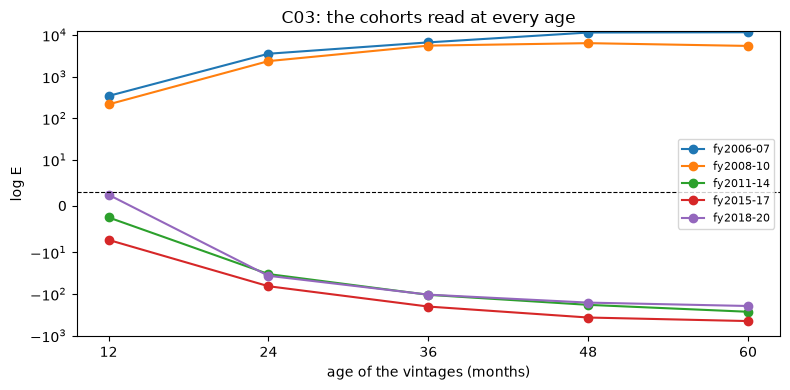

In [12]:
# C03: each cohort's vintages as the grades and the ages as the steps; the e-process from the committed curves
fig, ax = plt.subplots(figsize=(8, 4))
for c, o in c03.items():
    parts = [c03_seq.interval_counts(curve) for curve in o["vintage_curves"]]
    d, n, p = (np.stack([q[i] for q in parts], axis=1) for i in range(3))
    res = pd_grades.pd_grade_eprocess(d, n, p, direction="upper", combine="average")
    months = o["sequential"]["months"]
    month = None if res.rejection_time is None else months[res.rejection_time - 1]
    lights = [v["five_year_light"] for v in o["sequential"]["vintages"]]
    print(f"{c}: first age rejected (months) {month} | max log E {res.log_e.max():.1f} | 5-year lights {lights}")
    ax.plot(months, res.log_e, "o-", label=c)
ax.axhline(np.log(20), color="black", linestyle="--", linewidth=0.8)
ax.set_yscale("symlog", linthresh=10)
ax.set_xticks([12, 24, 36, 48, 60])
ax.set_xlabel("age of the vintages (months)")
ax.set_ylabel("log E")
ax.set_title("C03: the cohorts read at every age")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The cohorts of 2006 to 2007 and 2008 to 2010, which met the crisis, are rejected at the first age, 12 months, 48 months before
the fixed reading at five years that turned the binomial light of the 2006 to 2009 vintages red; their log E reaches 11,631 and 6,363. The cohorts of 2011 to
2014 and 2015 to 2017, which the model over-predicts, fall far below zero and are never rejected, and the 2018 to 2020 cohort rises
to 2.4 at 12 months, under the threshold of 3.0, and then falls: its 2018 vintage alone crosses at 12 months, the average of three
vintages does not. The null of this monitor is a binomial with no asset correlation, like the binomial test beside it, so a
rejection says the counts are too high for independent defaults, not that the model is wrong by that much.

## Results

**Answer:** Read every day for 1,000 days, Kupiec's test rejects a correct VaR in 66.5 % of the series on a trailing window and
33.8 % on all the days so far, and the traffic light leaves green in 58.7 %; the e-process rejects 1.8 %. It detects a hit rate three
and four times too high at a median of 244 and 129 days, and on the real hits of equity 2007 to 2009 it flags all 18 models at a
median of day 24. The price is power: at three times the rate it loses 11.9 points against one Kupiec reading at 250 days, above the
10 allowed, so the claim as stated does not hold, and a PD error of 10 % is detected in at most 60.0 % of the books where a single
chi-square at year 10 detects them all.

## Summary

- A test valid when read once loses its size when read every day; over 1,000 days a correct VaR fails Kupiec's test in up to
  66.5 % of the series.
- An e-process is an average of bets with mean 1 under the null, and Ville's inequality keeps its size at 5 % at any stopping time;
  the measured size is 1.8 %.
- It reads earlier than the 250-day light on real hits (median day 24 in 2007 to 2009) and misses two models with 5 exceptions in the
  euro in 2008.
- The cost is power at a fixed horizon, 11.9 points at three times the hit rate, which fails the rule fixed before the run, and more
  for a small PD error.

## References

- Ramdas, A., Grunwald, P., Vovk, V. and Shafer, G. (2023), Game-theoretic statistics and safe anytime-valid inference, Statistical Science 38(4). https://arxiv.org/abs/2210.01948
- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- riskvalidation 1.1.0, `validation.sequential` and its page. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/sequential/README.md